# Rule-based image classification

*Section 4 — Image classification, notebook 1 of 4.* Previous: `03_vector_data_and_zonal_stats/02_semivariograms`. Next: `02_unsupervised_classification`.

**You will learn:**
- how to calculate spectral indices (NDVI and MNDWI) with `calc_indices` and use them as extra classification features;
- how to write a rule base as a muParser expression and apply it with `band_maths`;
- how to plot the histogram of an index image with `plot_img_histogram` to choose a threshold;
- how to make a thematic (class) image with class names and colours in one call (`set_thematic_classes`) and map it beside the input image, with a legend, using `create_map_panels`;
- why defining rules is an iterative process, and how the rule order matters.

**Before you start:** you should be familiar with band maths and making maps from `01_getting_started` and `02_making_maps`.

**Data:** `../data/sen2_20180629_t30uvd_orb037_osgb_stdsref_20m.tif` (Sentinel-2, 20 m, 10 bands) and its valid-pixel mask `../data/sen2_20180629_t30uvd_orb037_osgb_stdsref_20m_vmsk.tif`.

**Run time:** about 1 minute.

## Introduction

A machine learning (supervised) classifier is not the only way of classifying imagery. Another commonly used method is a rule base. This is also a supervised classifier, but rather than selecting training pixels to train a classifier, you write a set of rules which are applied to the input data. Rule bases often take a considerable amount of time and effort to create, as you need to define rules which identify each class uniquely from the others (i.e., split up the feature space). However, as you can directly change the rules, they make it easier to understand and change the classification result.

In this notebook we will undertake a simple pixel-level rule-based classification using the `band_maths` function in the `rsgispy.imagecalc.maths` module.

## Running the notebook

The notebook has been run and saved with its outputs, so you can see what the outputs should look like and browse it online without running it.

If you run the notebook yourself, it is a good idea to clear the stored outputs first: in JupyterLab use *Edit > Clear Outputs of All Cells*, or in the classic Notebook *Cell > All Output > Clear*.

# 1. Import relevant modules

In [1]:
# Import the matplotlib plotting module and set it to work within
# a notebook environment.
%matplotlib inline

import os

import numpy
import rasterio

import rsgispy
import rsgispy.mapping.layout as map_layout
from rsgispy.imagecalc.calcindices import calc_indices
from rsgispy.imagecalc.maths import BandDefn, band_maths
from rsgispy.imageutils.colourtable import set_thematic_classes
from rsgispy.imageutils.metadata import get_band_names
from rsgispy.tools.plotting import plot_img_histogram

# 2. Define the input image and the output directory

In [2]:
# Input Sentinel-2 image file with 20 m resolution pixels.
input_img = "../data/sen2_20180629_t30uvd_orb037_osgb_stdsref_20m.tif"

# A valid pixel mask for the input image - this is required for later
# steps but note that for this particular image all the pixel values
# are valid (i.e., there are no 'no data' regions).
in_msk_img = "../data/sen2_20180629_t30uvd_orb037_osgb_stdsref_20m_vmsk.tif"

# All the outputs of this notebook are written to this directory.
out_dir = "outputs"
os.makedirs(out_dir, exist_ok=True)

The image has 10 bands, which have names stored in the file:

In [3]:
for i, band_name in enumerate(get_band_names(input_img)):
    print(f"{i + 1}: {band_name}")

1: Blue
2: Green
3: Red
4: RE_B5
5: RE_B6
6: RE_B7
7: NIR_B8
8: NIR_B8A
9: SWIR1
10: SWIR2


# 3. Create useful indices

It is often useful to calculate indices, such as the Normalised Difference Vegetation Index (NDVI) and a water index, and to include them in a classification, whether that is a rule base or a supervised machine learning classifier. Adding extra layers of relevant information like this is commonly referred to as *feature engineering*.

A normalised difference index combines two bands so that the result is in the range -1 to 1 and is less sensitive to illumination than the bands themselves:

$$
\text{NDVI} = \frac{\text{NIR} - \text{Red}}{\text{NIR} + \text{Red}} \qquad
\text{MNDWI} = \frac{\text{Green} - \text{SWIR1}}{\text{Green} + \text{SWIR1}}
$$

Vegetation reflects strongly in the near infrared (NIR) and absorbs red light, so it has a high NDVI. Water absorbs strongly in the short-wave infrared (SWIR), so it has a high (modified) Normalised Difference Water Index (MNDWI, also known as the GMNDWI).

The `calc_indices` function calculates any number of indices in one pass, writing one band per index. You tell it which band of the image is which with the `band_names` dictionary (band number: band name); the names it understands and the indices available can be listed with `get_available_indices()`.

> **RSGISLib users:** the separate `calc_ndvi`, `calc_gmndwi`, ... functions are replaced by this one function.

In [4]:
# The output image, with one band per index.
indices_img = os.path.join(out_dir, "sen2_20180629_aber_indices.tif")

calc_indices(
    input_img,
    indices_img,
    band_names={2: "green", 3: "red", 8: "nir", 9: "swir1"},
    indices=["NDVI", "GMNDWI"],
    no_data_val=0,  # input pixels with a value of 0 are no data
    out_no_data_val=-999,
    use_pbar=False,  # no progress bar (set to True to see progress)
)
print(get_band_names(indices_img))

['NDVI', 'GMNDWI']


# 4. Define the `band_maths` band definitions

To use the bands in an expression, each band is given a variable name with a `BandDefn` object (variable name, image file, band number). The bands can come from different images, as long as they are on the same pixel grid.

In [5]:
band_defns = list()
band_defns.append(BandDefn("vmsk", in_msk_img, 1))
band_defns.append(BandDefn("ndvi", indices_img, 1))
band_defns.append(BandDefn("ndwi", indices_img, 2))
band_defns.append(BandDefn("blue", input_img, 1))
band_defns.append(BandDefn("green", input_img, 2))
band_defns.append(BandDefn("red", input_img, 3))
band_defns.append(BandDefn("re_b5", input_img, 4))
band_defns.append(BandDefn("re_b6", input_img, 5))
band_defns.append(BandDefn("re_b7", input_img, 6))
band_defns.append(BandDefn("nir_b8", input_img, 7))
band_defns.append(BandDefn("nir_b8a", input_img, 8))
band_defns.append(BandDefn("swir1", input_img, 9))

# 5. Create rule base expression

First we need to understand the [if-else expression](https://beltoforion.de/en/muparser/features.php#idDef3) syntax of muParser (used by `band_maths`), as this will be how we define our rules:

> `<expression>?<true value>:<false value>`

> `if <expression> then <true value> else <false value>`

The `<false value>` can itself be another if-else expression, so a chain of these gives a list of rules which are tested in order. As the expression is likely to get long, it is worth remembering that Python allows a string to be built across multiple lines:

In [6]:
example_str = ("Hello " +
               "World")
print(example_str)

Hello World


## 5.1 How to define rules

This is the difficult bit, which requires expert knowledge of both the domain and the imagery you are using. Even with that expert knowledge, it is usually a very time consuming process.

When trying to define the rules for a class you need to look at the pixel values and find a range of values which uniquely defines that class. For example, to define a 'Water' class we would probably look for a threshold in the water index (MNDWI). Open the indices image in a GIS (e.g., QGIS) and click on pixels to see their values and estimate what this threshold should be. A histogram of the values is also useful: water pixels form a separate peak at the upper end. `plot_img_histogram` calculates the histogram of an image band block by block (so it works for images of any size), ignoring the no data value (-999) stored in the image:

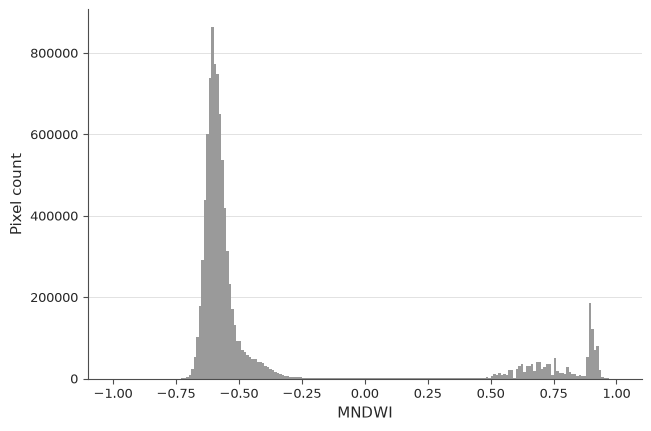

In [7]:
fig, ax = plot_img_histogram(
    indices_img,
    img_band=2,  # band 2 is the MNDWI
    n_bins=200,
    val_range=(-1, 1),
    x_label="MNDWI",
    use_pbar=False,
)

Initially let's try a value of `> 0.5`, where the class water will have an output value of 9 to be consistent with the other classification notebooks. Pixels outside the valid mask, and pixels not matched by any rule, get a value of 0 (no class).

In [8]:
exp = ("vmsk==0?0:" +
       "ndwi>0.5?9:" +
       "0")

In [9]:
print(exp)

vmsk==0?0:ndwi>0.5?9:0


## 5.2 Test the initial water classification

In [10]:
init_water_cls_img = os.path.join(out_dir, "init_water_cls_v1.tif")
band_maths(
    init_water_cls_img,
    exp,
    band_defns,
    gdalformat="GTIFF",
    datatype=rsgispy.TYPE_8UINT,
    use_pbar=False,
)

To help visualisation, the output is marked as a *thematic* image (i.e., an integer image of discrete classes rather than continuous values), with a name and a colour for each class, and then image statistics and pyramids are calculated (with 0 as the no data value). `set_thematic_classes` does all of this in one call: it takes a dictionary of `{pixel value: (class name, colour)}`, writes the colours to the image colour table and stores the class names in the image file, where the mapping functions find them for the legend.

In [11]:
set_thematic_classes(init_water_cls_img, {9: ("Water", "#0000ff")})

### Visualise initial water classification

You will probably be best opening the result in QGIS to look at it interactively, but below provides an initial look at the result. `create_map_panels` draws maps side by side with the same extent: here the input image (an `'rgb'` panel of the NIR, SWIR1 and red bands) and the classification (a `'thematic'` panel). It adds one scale bar and north arrow, and a legend of the classes of the thematic panels, using the class names stored by `set_thematic_classes`.

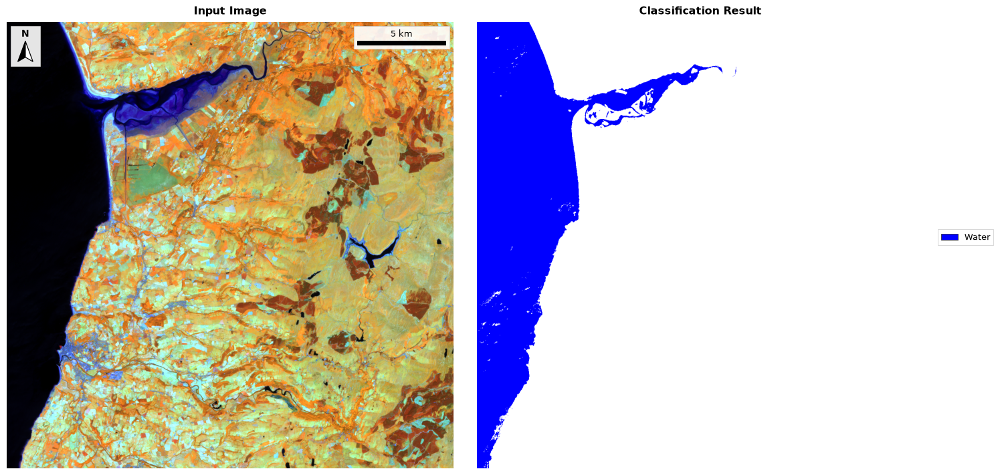

In [12]:
# Define a bbox (xmin, xmax, ymin, ymax) for the subset to be displayed
sub_img_bbox = [255000, 280000, 275000, 300000]

fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel("rgb", input_img, bands=[8, 9, 3], title="Input Image"),
        map_layout.MapPanel("thematic", init_water_cls_img, title="Classification Result"),
    ],
    bbox=sub_img_bbox,
    figsize=(14, 7),
)

I would interpret this result as having worked for the sea, but not for the inland water bodies. Try lowering the threshold, e.g., `ndwi > 0.1`.

## 5.3 Updating water classification

In [13]:
exp = ("vmsk==0?0:" +
       "ndwi>0.1?9:" +
       "0")

In [14]:
init_water_cls_img = os.path.join(out_dir, "init_water_cls_v2.tif")
band_maths(
    init_water_cls_img,
    exp,
    band_defns,
    gdalformat="GTIFF",
    datatype=rsgispy.TYPE_8UINT,
    use_pbar=False,
)
set_thematic_classes(init_water_cls_img, {9: ("Water", "#0000ff")})

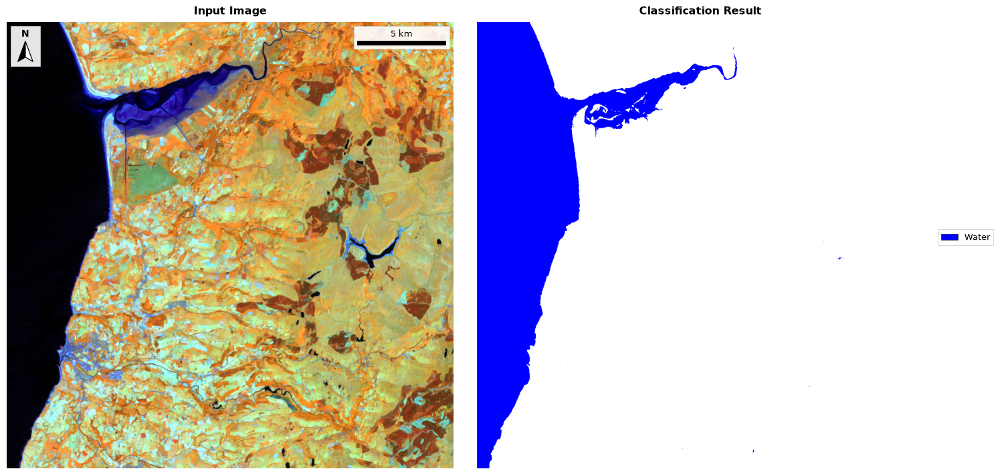

In [15]:
fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel("rgb", input_img, bands=[8, 9, 3], title="Input Image"),
        map_layout.MapPanel("thematic", init_water_cls_img, title="Classification Result"),
    ],
    bbox=sub_img_bbox,
    figsize=(14, 7),
)

This has improved the classification in some areas, but maybe the threshold should be lowered further. Try the following thresholds:

 * 0.0
 * -0.1
 * -0.2
 * -0.3
 * -0.4
 * -0.5

What did you observe when you tried these different thresholds? What do you think the optimal threshold is for classifying water while not misclassifying other land covers?

# 6. Including multiple classes

## 6.1 Initial set of rules

Right, let's create some rules for the water class (9), conifer forest (3) and bare rock and sand (2).

In [16]:
exp = (
    "vmsk==0?0:" +
    "ndwi>-0.25?9:" +
    "(ndwi>-0.45)&&(ndvi>0.2)?3:" +
    "(ndwi>-0.5)&&(ndvi<0.2)?2:" +
    "0"
)

We also need a name and a colour for each of the new classes (water stays blue):

In [17]:
init_multi_cls_img = os.path.join(out_dir, "multi_cls_rslt_v1.tif")
band_maths(
    init_multi_cls_img,
    exp,
    band_defns,
    gdalformat="GTIFF",
    datatype=rsgispy.TYPE_8UINT,
    use_pbar=False,
)
set_thematic_classes(
    init_multi_cls_img,
    {
        2: ("Bare_Rock_Sand", "#e31a1c"),
        3: ("Conifer_Forest", "#33a02c"),
        9: ("Water", "#0000ff"),
    },
)

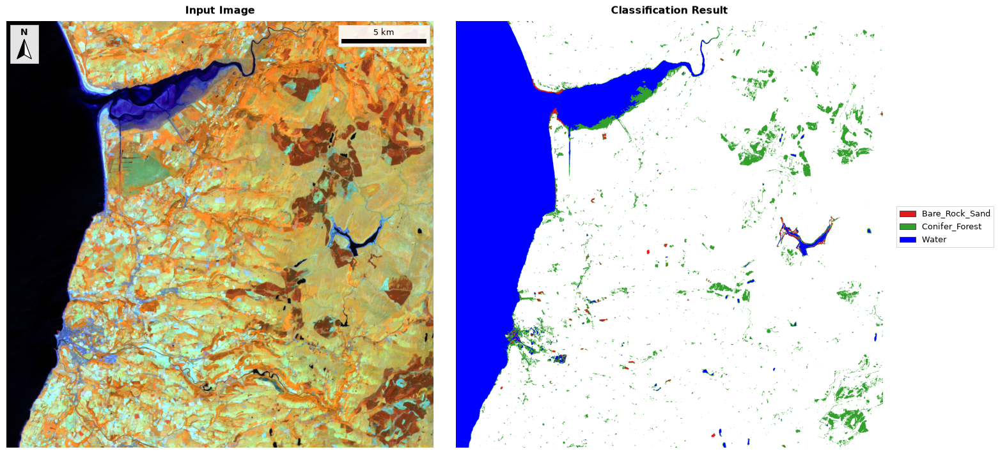

In [18]:
fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel("rgb", input_img, bands=[8, 9, 3], title="Input Image"),
        map_layout.MapPanel("thematic", init_multi_cls_img, title="Classification Result"),
    ],
    bbox=sub_img_bbox,
    figsize=(14, 7),
)

How do you think the initial set of thresholds worked? To me, it looks like there is quite a bit of error. To improve this we need to refine our thresholds...

Hopefully, what you are getting from this exercise is that working out your thresholds is an iterative process which can be very time consuming.

## 6.2 Refining the set of rules

In [19]:
exp = (
    "vmsk==0?0:" +
    "ndwi>-0.25?9:" +
    "(ndwi>-0.45)&&(ndvi>0.6)?3:" +
    "(ndwi>-0.5)&&(ndvi<0.5)?2:" +
    "0"
)

In [20]:
init_multi_cls_img = os.path.join(out_dir, "multi_cls_rslt_v2.tif")
band_maths(
    init_multi_cls_img,
    exp,
    band_defns,
    gdalformat="GTIFF",
    datatype=rsgispy.TYPE_8UINT,
    use_pbar=False,
)
set_thematic_classes(
    init_multi_cls_img,
    {
        2: ("Bare_Rock_Sand", "#e31a1c"),
        3: ("Conifer_Forest", "#33a02c"),
        9: ("Water", "#0000ff"),
    },
)

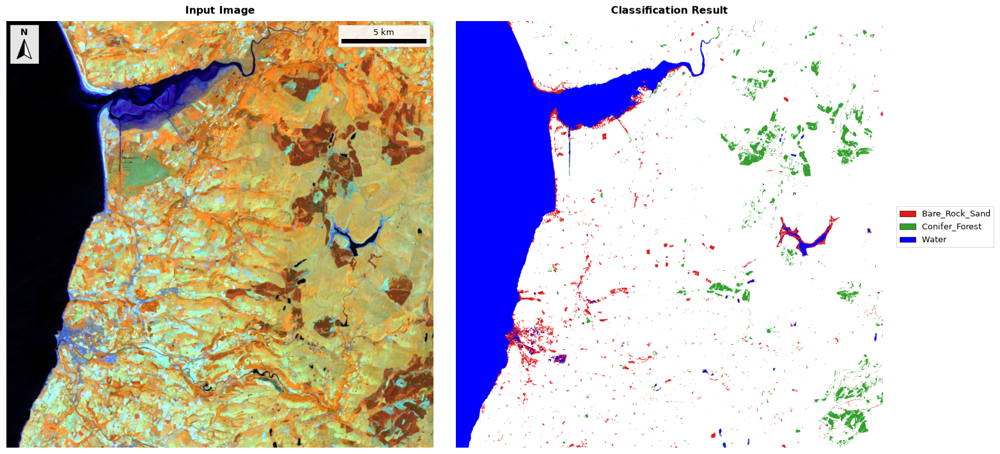

In [21]:
fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel("rgb", input_img, bands=[8, 9, 3], title="Input Image"),
        map_layout.MapPanel("thematic", init_multi_cls_img, title="Classification Result"),
    ],
    bbox=sub_img_bbox,
    figsize=(14, 7),
)

# 7. Define class names and colours

So far we have made up a name and a colour for each class as we went along. It is much easier to interpret and compare the classifications if there is one consistent set of class names and colours, used for every classification and therefore for every map legend. So let's define the full list of classes (the same as in the other classification notebooks) in a dictionary, `{pixel value: (class name, colour)}`. Colours can be given as hexadecimal strings (`"#RRGGBB"`) or `(red, green, blue)` tuples with values between 0 and 255.

> **RSGISLib users:** RSGISLib stored the class names and colours in the raster attribute table (`rastergis.set_class_names_colours`). GeoTIFF files have no attribute table in rsgispy: `set_thematic_classes` writes the colours to the image colour table and stores the names in the GeoTIFF as a band tag (read them back with `get_thematic_classes`), where the map and legend functions find them.

In [22]:
class_info = {
    1: ("Artificial_Surfaces", (160, 160, 160)),
    2: ("Bare_Rock_Sand", (100, 100, 100)),
    3: ("Conifer_Forest", (2, 97, 16)),
    4: ("Deciduous_Forest", (50, 184, 69)),
    5: ("Grass_Long", (150, 227, 18)),
    6: ("Grass_Short", (194, 219, 66)),
    7: ("NonPhoto_Veg", (98, 225, 227)),
    8: ("Scrub", (0, 80, 0)),
    9: ("Water", (0, 0, 255)),
    10: ("Bracken", (235, 146, 38)),
}

set_thematic_classes(init_multi_cls_img, class_info)

The legend lists only the classes found in the map, with the names and colours of `class_info`:

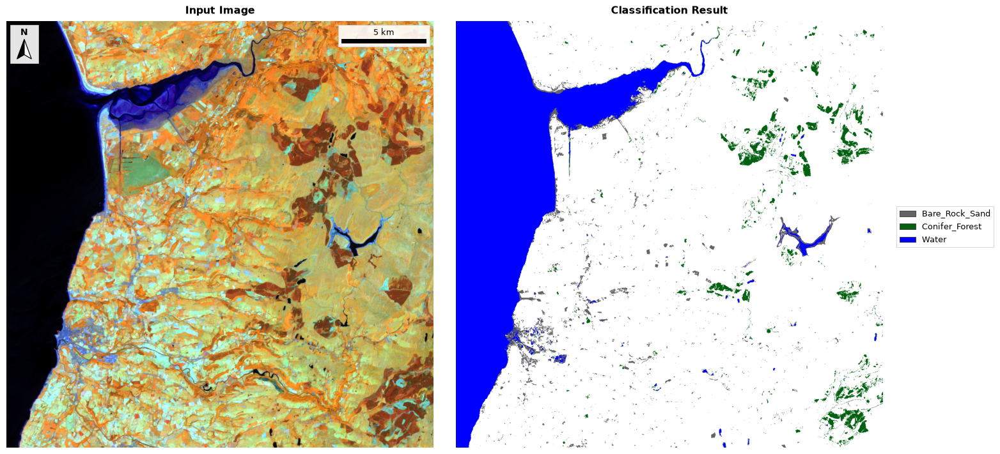

In [23]:
fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel("rgb", input_img, bands=[8, 9, 3], title="Input Image"),
        map_layout.MapPanel("thematic", init_multi_cls_img, title="Classification Result"),
    ],
    bbox=sub_img_bbox,
    figsize=(14, 7),
)

From now on, `set_thematic_classes` is run with `class_info` after each classification, so the names and colours are the same in every result.

# 8. Improving the classification

Try editing the rules below to improve the classification of the three classes, then run the cells to see the result.

In [24]:
exp = (
    "vmsk==0?0:" +
    "ndwi>-0.25?9:" +
    "(ndwi>-0.45)&&(ndvi>0.6)?3:" +
    "(ndwi>-0.5)&&(ndvi<0.5)?2:" +
    "0"
)

In [25]:
init_multi_cls_img = os.path.join(out_dir, "multi_cls_rslt_v3.tif")
band_maths(
    init_multi_cls_img,
    exp,
    band_defns,
    gdalformat="GTIFF",
    datatype=rsgispy.TYPE_8UINT,
    use_pbar=False,
)
set_thematic_classes(init_multi_cls_img, class_info)

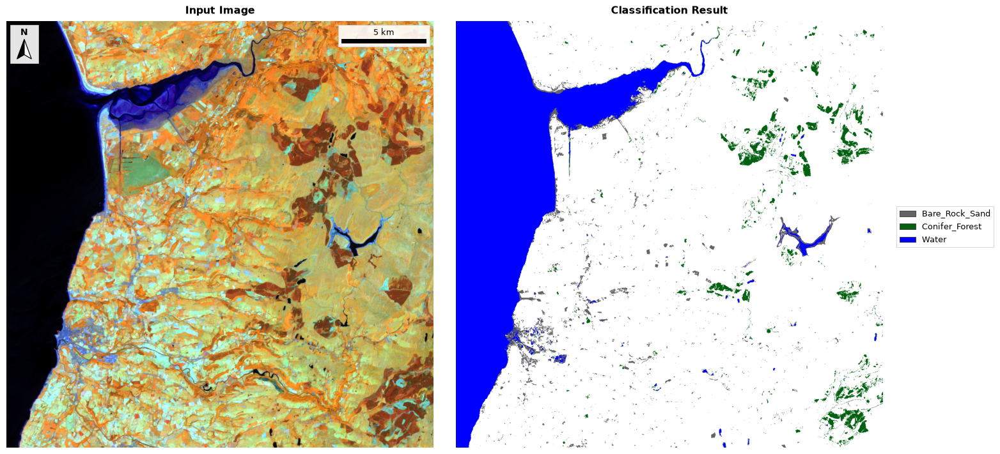

In [26]:
fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel("rgb", input_img, bands=[8, 9, 3], title="Input Image"),
        map_layout.MapPanel("thematic", init_multi_cls_img, title="Classification Result"),
    ],
    bbox=sub_img_bbox,
    figsize=(14, 7),
)

# 9. Complete classification

OK, now let's create a rule base which classifies all the classes. These rules use the reflectance bands as well as the indices (the reflectance values in this image are scaled by 1000, so e.g. `swir1<=27` means a SWIR1 reflectance of at most 0.027).

In [27]:
exp = (
    "vmsk==0?0:" +
    "swir1<=27?9:" +
    "(swir1>27)&&(red<=25.5)&&(nir_b8<=401)?3:" +
    "(swir1>27)&&(red<=25.5)&&(nir_b8>401)?4:" +
    "(swir1>27)&&(red>25.5)&&(nir_b8<=553.50)&&(swir1<=331.50)&&(ndvi<=0.52)&&(nir_b8a<=175.50)?2:" +
    "(swir1>27)&&(red>25.5)&&(nir_b8<=553.50)&&(swir1<=331.50)&&(ndvi<=0.52)&&(nir_b8a>175.50)?1:" +
    "(swir1>27)&&(red>25.5)&&(nir_b8<=553.50)&&(swir1<=331.50)&&(ndvi>0.52)?8:" +
    "(swir1>27)&&(red>25.5)&&(nir_b8<=553.50)&&(swir1>331.50)&&(re_b7<=405)?7:" +
    "(swir1>27)&&(red>25.5)&&(nir_b8<=553.50)&&(swir1>331.50)&&(re_b7>405)?6:" +
    "(swir1>27)&&(red>25.5)&&(nir_b8>553.50)&&(swir1<=244.5)?5:" +
    "(swir1>27)&&(red>25.5)&&(nir_b8>553.50)&&(swir1>244.5)?10:" +
    "0"
)

In [28]:
full_cls_img = os.path.join(out_dir, "multi_cls_rslt_full.tif")
band_maths(
    full_cls_img,
    exp,
    band_defns,
    gdalformat="GTIFF",
    datatype=rsgispy.TYPE_8UINT,
    use_pbar=False,
)
set_thematic_classes(full_cls_img, class_info)

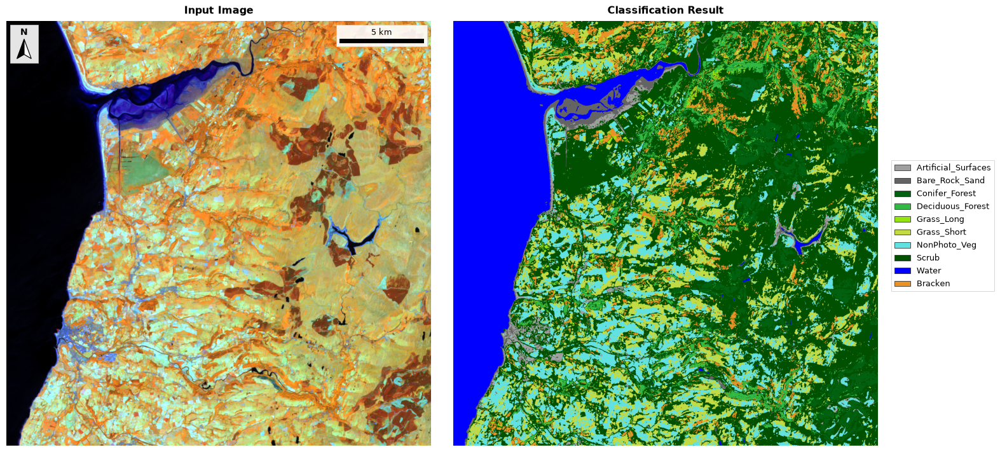

In [29]:
fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel("rgb", input_img, bands=[8, 9, 3], title="Input Image"),
        map_layout.MapPanel("thematic", full_cls_img, title="Classification Result"),
    ],
    bbox=sub_img_bbox,
    figsize=(14, 7),
)

We can also count the number of pixels in each class, which gives the area of each class (each pixel is 20 x 20 m, i.e. 0.04 ha):

In [30]:
with rasterio.open(full_cls_img) as ds:
    cls_arr = ds.read(1)

vals, counts = numpy.unique(cls_arr[cls_arr > 0], return_counts=True)
for val, count in zip(vals, counts):
    print(f"{class_info[val][0]:20s} {count * 0.04:10.1f} ha")

Artificial_Surfaces      3515.8 ha
Bare_Rock_Sand           1556.2 ha
Conifer_Forest          18903.5 ha
Deciduous_Forest        17931.5 ha
Grass_Long               8771.4 ha
Grass_Short             31507.0 ha
NonPhoto_Veg            28472.4 ha
Scrub                  178828.1 ha
Water                   52741.5 ha
Bracken                 37126.2 ha


## 9.1 Conclusions

OK. So how good is the final classification produced during this notebook? Clearly there is quite a large over-classification of scrub (the dark green, easily mistaken for conifer forest; see the areas above). Can you figure out why this is? Can you fix it? (Changing the scrub colour in `class_info` may help you see it.)

Also, note that the rules are run in order: if a pixel meets the conditions of an earlier rule then that one is applied and the rest are not. If you were to look at the values of a particular pixel you could easily follow through the rules and identify why it was classified as it was. This is particularly useful for pixels which have been incorrectly classified (i.e., confused with another class).

Rule bases can be a really powerful way to classify a dataset, allowing datasets of different modalities (e.g., reflectance, elevation, slope etc.) to be combined in a meaningful way, and their explainability makes them a popular classification method. But for large rule bases considerable time is required to define the rules. In the next notebooks we will let the computer find groups in the data (unsupervised classification) and then learn the rules from training data (supervised machine learning).